In [ ]:
!gdown 1L5tv0TIc2O4cyaamoiT_leZvqhC86Pc3

Downloading...
From (original): https://drive.google.com/uc?id=1L5tv0TIc2O4cyaamoiT_leZvqhC86Pc3
From (redirected): https://drive.google.com/uc?id=1L5tv0TIc2O4cyaamoiT_leZvqhC86Pc3&confirm=t&uuid=9a71ac14-3d5c-487c-a8e8-2d68106ab15c
To: /content/dataset.zip
100% 11.8G/11.8G [01:58<00:00, 99.5MB/s]


In [ ]:
!unzip -q dataset.zip -d dataset/

In [ ]:
%%shell
for f in dataset/*.zip; do
  unzip -q "$f" -d "${f%.zip}"
done

In [ ]:
!pip install mne -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 41.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


Extracting BDF parameters from dataset/M1_1/M1_1/M1resting.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 407551  =      0.000 ...   795.998 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, AFp1, AF7, AF3, AFF5h, AFF1h, F9, F7, F5, F3, F1, FFT9h, ...
 chs: 143 EEG, 1 Stimulus
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 104.0 Hz
 meas_date: 2018-02-08 16:12:12 UTC
 nchan: 144
 projs: []
 sfreq: 512.0 Hz
 subject_info: <subject_info | his_id: >
>
Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


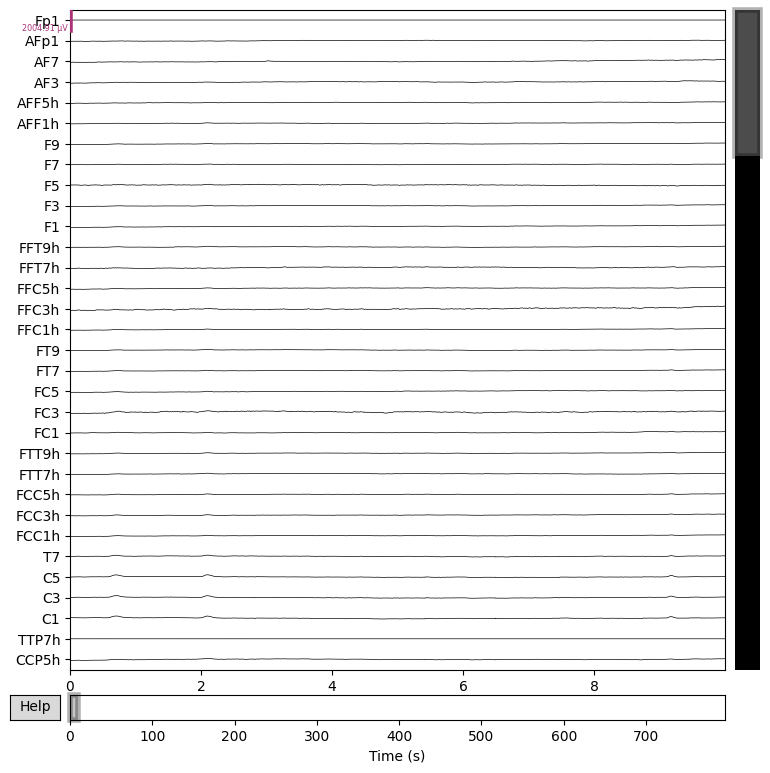

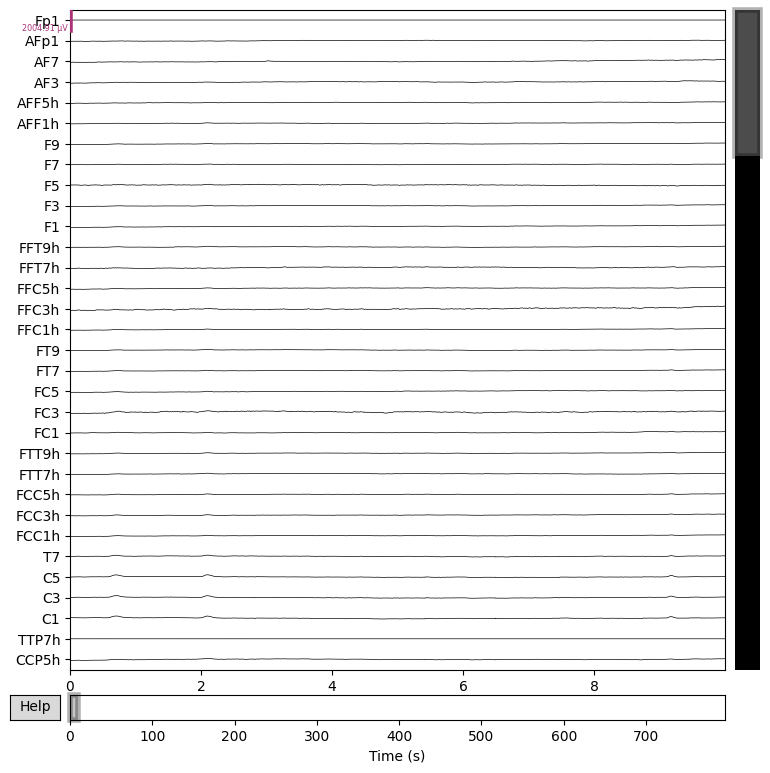

In [ ]:
import mne
import os

bdf_path = 'dataset/M1_1/M1_1/M1resting.bdf'
raw = mne.io.read_raw_bdf(bdf_path, preload=True)
print(raw.info)

raw.plot(duration=10, n_channels=32, scalings='auto')

In [ ]:
import os
import glob

exclusions = ['M2', 'M6', 'M13', 'M18']
all_subdirs = [d for d in glob.glob('/content/dataset/*') if os.path.isdir(d)]

valid_dirs = []
for d in all_subdirs:
    folder_name = os.path.basename(d)
    if (folder_name.startswith('M') or folder_name.startswith('C')):
        if not any(excl == folder_name.split('_')[0] for excl in exclusions):
            valid_dirs.append(d)

print(f'Found {len(valid_dirs)} valid subject directories.')
print('Example directories:', valid_dirs[:5])

Found 35 valid subject directories.
Example directories: ['/content/dataset/C18', '/content/dataset/M14_1', '/content/dataset/M8_2', '/content/dataset/C17', '/content/dataset/C3']


In [ ]:
valid_dirs

['/content/dataset/C18',
 '/content/dataset/M14_1',
 '/content/dataset/M8_2',
 '/content/dataset/C17',
 '/content/dataset/C3',
 '/content/dataset/C7',
 '/content/dataset/M16_1',
 '/content/dataset/M5_1',
 '/content/dataset/C2',
 '/content/dataset/C13',
 '/content/dataset/C15',
 '/content/dataset/M11_1',
 '/content/dataset/M7_1',
 '/content/dataset/M1_1',
 '/content/dataset/C10',
 '/content/dataset/C5',
 '/content/dataset/C20',
 '/content/dataset/M4_1',
 '/content/dataset/C21',
 '/content/dataset/M3_2',
 '/content/dataset/C9',
 '/content/dataset/M9_2',
 '/content/dataset/C4',
 '/content/dataset/C1',
 '/content/dataset/M17_1',
 '/content/dataset/C6',
 '/content/dataset/C14',
 '/content/dataset/C12',
 '/content/dataset/C8',
 '/content/dataset/M12_2',
 '/content/dataset/C11',
 '/content/dataset/C16',
 '/content/dataset/C19',
 '/content/dataset/M15_2',
 '/content/dataset/M10_1']

In [ ]:
import os
import gc
from tqdm import tqdm

os.makedirs("processed_data", exist_ok=True)
file_paths, labels = [], []

for subj_dir in tqdm(valid_dirs):
    label = 1 if 'M' in os.path.basename(subj_dir) else 0

    for task_file in glob.glob(f"{subj_dir}/**/*.bdf", recursive=True):
        try:
            raw = preprocess_eeg(task_file)
            spec = generate_spectrograms(raw)
            spec_fixed = resize_spectrogram(spec, target_length=2000)

           
            spec_fixed = spec_fixed.astype(np.float32)

          
            file_id = os.path.basename(task_file).replace('.bdf', '.npy')
            save_path = os.path.join("processed_data", file_id)
            np.save(save_path, spec_fixed)

            file_paths.append(save_path)
            labels.append(label)

            del raw, spec, spec_fixed
            gc.collect()

        except Exception as e:
            print(f"Error processing {task_file}: {e}")

100%|██████████| 35/35 [21:23<00:00, 36.68s/it]


In [ ]:
import os
import gc
import glob
import math
import numpy as np
from tqdm import tqdm
from scipy.signal import spectrogram
from sklearn.model_selection import train_test_split

import mne
import tensorflow as tf
from tensorflow.keras import layers, models, constraints
from tensorflow.keras.utils import Sequence

In [ ]:


mne.set_log_level('WARNING')

def preprocess_eeg(filepath):
    raw = mne.io.read_raw_bdf(filepath, preload=True, verbose=False)
    raw.pick('eeg', verbose=False)
    raw.set_eeg_reference('average', projection=False, verbose=False)
    raw.filter(l_freq=1.0, h_freq=50.0, verbose=False)
    raw.notch_filter(60.0, verbose=False)

    return raw

def generate_spectrograms(raw):
    data = raw.get_data() * 1e6
    fs = raw.info['sfreq']
    frequencies, times, Sxx = spectrogram(data, fs=fs, nperseg=256, noverlap=128)

    Sxx_db = 10 * np.log10(Sxx + 1e-6)
    return Sxx_db

def resize_spectrogram(spec, target_length=2000):
    current_length = spec.shape[2]
    if current_length > target_length:
        return spec[:, :, :target_length]
    else:
        pad_width = target_length - current_length
        return np.pad(
            spec,
            ((0, 0), (0, 0), (0, pad_width)),
            mode='constant',
            constant_values=-100.0
        )

base_dir = "/content/dataset"

all_dirs = sorted(glob.glob(f"{base_dir}/M*") + glob.glob(f"{base_dir}/C*"))

exclusions = ['M2', 'M6', 'M13', 'M18']
valid_dirs = [d for d in all_dirs if not any(excl in os.path.basename(d) for excl in exclusions)]

os.makedirs("processed_data", exist_ok=True)
file_paths, labels = [], []

print(f"Processing {len(valid_dirs)} subject directories...")

for subj_dir in tqdm(valid_dirs, desc="Subjects"):
    label = 1 if 'M' in os.path.basename(subj_dir) else 0

    # Discover all task files (.bdf) for the subject
    for task_file in glob.glob(f"{subj_dir}/**/*.bdf", recursive=True):
        file_id = os.path.basename(task_file).replace('.bdf', '.npy')
        save_path = os.path.join("processed_data", file_id)

        if not os.path.exists(save_path):
            try:
                raw = preprocess_eeg(task_file)
                spec = generate_spectrograms(raw)
                spec_fixed = resize_spectrogram(spec, target_length=2000)
                spec_fixed = spec_fixed.astype(np.float32)
                np.save(save_path, spec_fixed)
                del raw, spec, spec_fixed
                gc.collect()

            except Exception as e:
                print(f"\nError processing {task_file}: {e}")
                continue

        file_paths.append(save_path)
        labels.append(label)

print(f"\nTotal samples saved: {len(file_paths)}")

Processing 36 subject directories...


Subjects: 100%|██████████| 36/36 [23:26<00:00, 39.06s/it]


Total samples saved: 106


Total processed files found: 106
Migraine Class (1): 39 samples
Control Class (0):  67 samples


/tmp/ipykernel_9019/3925141449.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Control (0)', 'Migraine (1)'], y=[control_count, migraine_count], palette='viridis')


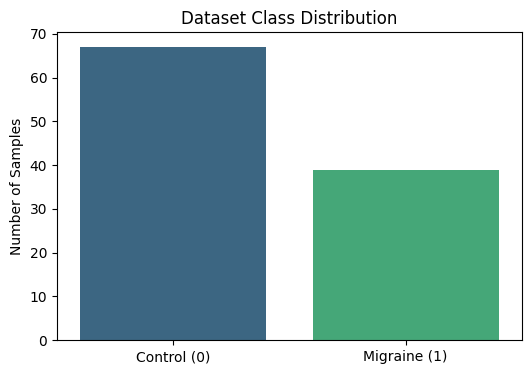

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

data_dir = "processed_data"
npy_files = np.array(glob.glob(os.path.join(data_dir, "*.npy")))

# Extract labels: 'M' = 1 (Migraine), 'C' = 0 (Control)
labels = np.array([1 if 'M' in os.path.basename(f) else 0 for f in npy_files])

migraine_count = np.sum(labels == 1)
control_count = np.sum(labels == 0)

print(f"Total processed files found: {len(npy_files)}")
print(f"Migraine Class (1): {migraine_count} samples")
print(f"Control Class (0):  {control_count} samples")

plt.figure(figsize=(6, 4))
sns.barplot(x=['Control (0)', 'Migraine (1)'], y=[control_count, migraine_count], palette='viridis')
plt.title('Dataset Class Distribution')
plt.ylabel('Number of Samples')
plt.show()

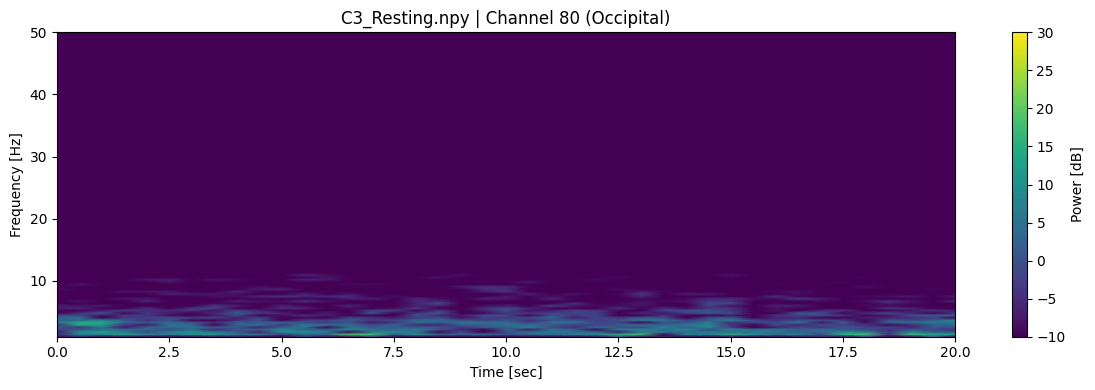

In [ ]:
def plot_sample(npy_filepath, channel_idx=80):
    spec_data = np.load(npy_filepath)
    single_channel = spec_data[channel_idx, :, :]

    freq_bins, time_bins = single_channel.shape
    frequencies = np.linspace(1, 50, freq_bins)
    times = np.linspace(0, time_bins / (256/128), time_bins)

    plt.figure(figsize=(12, 4))
    plt.pcolormesh(times, frequencies, single_channel, shading='gouraud', cmap='viridis', vmin=-10, vmax=30)
    plt.title(f'{os.path.basename(npy_filepath)} | Channel {channel_idx} (Occipital)')
    plt.ylabel('Frequency [Hz]')
    plt.xlabel('Time [sec]')
    plt.colorbar(label='Power [dB]')
    plt.xlim(0, 20)
    plt.tight_layout()
    plt.show()

if len(npy_files) > 0:
    plot_sample(npy_files[0], channel_idx=80)

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

def generate_cnn_images(npy_files, output_dir="cnn_spectrograms", channel_idx=80):
    migraine_dir = os.path.join(output_dir, "Migraine")
    control_dir = os.path.join(output_dir, "Control")
    os.makedirs(migraine_dir, exist_ok=True)
    os.makedirs(control_dir, exist_ok=True)

    print(f"Generating high-quality CNN images in ./{output_dir}/ ...")

    for npy_filepath in tqdm(npy_files):
        spec_data = np.load(npy_filepath)
        single_channel = spec_data[channel_idx, :, :]

        freq_bins, time_bins = single_channel.shape
        frequencies = np.linspace(1, 50, freq_bins)
        times = np.linspace(0, time_bins / (256/128), time_bins)
        fig = plt.figure(figsize=(10, 4), frameon=False)
        ax = plt.Axes(fig, [0., 0., 1., 1.])
        ax.set_axis_off()
        fig.add_axes(ax)
        ax.pcolormesh(times, frequencies, single_channel,
                      shading='gouraud', cmap='viridis',
                      vmin=-10, vmax=30)

        ax.set_xlim(0, 20)
        filename = os.path.basename(npy_filepath)
        target_folder = migraine_dir if 'M' in filename else control_dir
        img_filename = filename.replace('.npy', '.png')
        save_path = os.path.join(target_folder, img_filename)
        plt.savefig(save_path, dpi=600, format='png', bbox_inches='tight', pad_inches=0)
        plt.close(fig)

generate_cnn_images(npy_files, output_dir="cnn_spectrograms", channel_idx=80)

Generating high-quality CNN images in ./cnn_spectrograms/ ...


100%|██████████| 106/106 [09:08<00:00,  5.17s/it]
